<div style="background:linear-gradient(120deg,#1b3a2f 0%,#2f6f4e 100%);padding:34px 30px;border-radius:10px;color:white;font-family:'Segoe UI',system-ui,sans-serif;"><div style="font-family:Georgia,serif;font-size:13px;letter-spacing:3px;opacity:.85;text-transform:uppercase;">Trabajo Práctico Integrador · Minería de Datos</div><div style="font-family:Georgia,serif;font-size:30px;font-weight:700;margin-top:6px;">Etapa 2 — Versión resumida: un modelo de cada tipo</div><div style="font-size:18px;margin-top:12px;opacity:.95;">Aprendizaje <b>supervisado</b> con <b>Random Forest</b> · Aprendizaje <b>no supervisado</b> con <b>K-Means</b> (y PCA para visualizar)</div></div>

## 🎯 Qué hace este notebook

La consigna pide aplicar, justificar y documentar **al menos una técnica supervisada y una no supervisada**. Acá elegimos **una de cada una**:

| | Supervisado | No supervisado |
|---|---|---|
| **Algoritmo** | **Random Forest** | **K-Means** (+ PCA solo para *ver* los datos) |
| **Pregunta** | ¿Qué cultivo conviene sembrar en una parcela? | ¿Qué grupos naturales existen, sin mirar la etiqueta? |
| **Tipo de problema** | Clasificación (22 cultivos) | Agrupamiento (clustering) |
| **Datos** | Dataset A (suelo + clima) | Dataset A y Dataset B (estados de India) |

### 🤔 ¿Por qué estos dos?
**Random Forest** (en la versión completa lo comparamos con otros 5 algoritmos):
- Empata en precisión con el mejor (Naïve Bayes) y es **estable**.
- Da **probabilidades**, que permiten recomendar un cultivo **con alternativas** (Top-3).
- Mide qué variables usa, lo que permite comprobar que **ninguna domina**.

**K-Means**:
- Es el algoritmo de agrupamiento más conocido y fácil de explicar.
- Podemos **evaluarlo contra la realidad** (sabemos qué cultivo es cada parcela, aunque el algoritmo no lo vea).

> 🗂️ **Fuentes:** Dataset A = *Crop Recommendation* (Kaggle, `atharvaingle`). Dataset B = *Crop Production in India* (Ministerio de Agricultura de India, `data.gov.in`), limpiado en la Etapa 1-B y en el Taller 2b.

<div style="border-left:8px solid #2f6f4e;background:#f4f8f5;padding:16px 22px;margin:28px 0 12px 0;border-radius:0 8px 8px 0;"><div style="font-family:Georgia,serif;font-size:13px;letter-spacing:2px;color:#a04e14;font-weight:700;text-transform:uppercase;">Parte 1</div><div style="font-family:Georgia,serif;font-size:26px;font-weight:700;color:#143026;">Preparación</div><div style="font-family:'Segoe UI',system-ui,sans-serif;font-size:16px;color:#3d4f47;margin-top:4px;">Herramientas y datos</div></div>

<div style="border-left:6px solid #1565c0;background:#eef5fc;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15px;line-height:1.6;color:#14181a;"><b>📂 Dónde van los archivos (versión VS Code)</b><br>Todos los CSV están en la carpeta <code>datos/</code> junto a este notebook. Las celdas de carga <b>aceptan los archivos tanto en su versión original (inglés) como ya traducidos al castellano</b>, y lo que el notebook genera se guarda en <code>salida/</code>. Si algo falla, ejecutá primero <code>python verificar_proyecto.py</code>.</div>

In [1]:
import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore"); sns.set_style("whitegrid")
pd.options.display.float_format = "{:,.3f}".format
SEED = 42; np.random.seed(SEED)

from pathlib import Path

# --- Ubicación de archivos: busca en datos/, en la carpeta actual y en la carpeta superior ---
def ruta(nombre, alternativas=(), obligatorio=True):
    """Devuelve la ruta del primer archivo que exista (acepta nombres alternativos)."""
    for n in (nombre, *alternativas):
        for carpeta in (Path("datos"), Path("."), Path("../datos"), Path("..")):
            if (carpeta / n).exists():
                return carpeta / n
    if obligatorio:
        raise FileNotFoundError(
            f"No encuentro '{nombre}'.\n  Carpeta de trabajo actual: {Path.cwd()}\n"
            "  → Abrí la carpeta COMPLETA del proyecto en VS Code (File > Open Folder) "
            "y verificá que exista la subcarpeta datos/ (podés correr verificar_proyecto.py).")
    return None

SALIDA = Path("salida"); SALIDA.mkdir(exist_ok=True)

RUTAS = {
    "train":    ruta("train.csv"),
    "test":     ruta("test.csv"),
    "limpio_B": ruta("crop_production_LIMPIO.csv", ("crop_production_limpio_express.csv", "crop_production_limpio_castellano.csv")),
}
for k, v in RUTAS.items():
    print(f"  ✔ {k:9s} → {v}")
print("Entorno listo ✅")

  ✔ train     → datos/train.csv
  ✔ test      → datos/test.csv
  ✔ limpio_B  → datos/crop_production_limpio_express.csv
Entorno listo ✅


<div style="border-left:8px solid #2f6f4e;background:#f4f8f5;padding:16px 22px;margin:28px 0 12px 0;border-radius:0 8px 8px 0;"><div style="font-family:Georgia,serif;font-size:13px;letter-spacing:2px;color:#a04e14;font-weight:700;text-transform:uppercase;">Diccionario</div><div style="font-family:Georgia,serif;font-size:26px;font-weight:700;color:#143026;">Inglés → castellano</div><div style="font-family:'Segoe UI',system-ui,sans-serif;font-size:16px;color:#3d4f47;margin-top:4px;">Los archivos originales vienen en inglés; los traducimos al cargarlos para analizar mejor</div></div>

<div style="border-left:6px solid #2f6f4e;background:#f1f8f3;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🗣️ En criollo</b><br>Los datasets originales traen los nombres de cultivos en inglés (<code>rice</code>, <code>pigeonpeas</code>), las temporadas con palabras locales (<code>Kharif</code>, <code>Rabi</code>) y algunas columnas con códigos. Para <b>leer mejor los resultados y gráficos</b>, todo se traduce al castellano apenas se carga. <b>Los archivos originales no se modifican</b> (se conservan en inglés por trazabilidad con la fuente).</div>

In [2]:
COLUMNAS_A = {'Nitrogeno_N': 'Nitrógeno (N)',
 'Fosforo_P': 'Fósforo (P)',
 'Potasio_K': 'Potasio (K)',
 'Temperatura_C': 'Temperatura (°C)',
 'Humedad_pct': 'Humedad (%)',
 'pH_Suelo': 'pH del suelo',
 'Precipitacion_mm': 'Precipitación (mm)'}

CULT_A = {'apple': 'Manzana',
 'banana': 'Banana',
 'blackgram': 'Poroto negro',
 'chickpea': 'Garbanzo',
 'coconut': 'Coco',
 'coffee': 'Café',
 'cotton': 'Algodón',
 'grapes': 'Uva',
 'jute': 'Yute',
 'kidneybeans': 'Poroto rojo',
 'lentil': 'Lenteja',
 'maize': 'Maíz',
 'mango': 'Mango',
 'mothbeans': 'Poroto moth',
 'mungbean': 'Poroto mung',
 'muskmelon': 'Melón',
 'orange': 'Naranja',
 'papaya': 'Papaya',
 'pigeonpeas': 'Gandul',
 'pomegranate': 'Granada',
 'rice': 'Arroz',
 'watermelon': 'Sandía'}

CULT_B = {'Apple': 'Manzana',
 'Arecanut': 'Nuez de areca',
 'Ash Gourd': 'Calabaza cerosa',
 'Banana': 'Banana',
 'Barley': 'Cebada',
 'Bean': 'Poroto',
 'Beans & Mutter(Vegetable)': 'Porotos y arvejas (hortaliza)',
 'Beet Root': 'Remolacha',
 'Ber': 'Ber (azufaifo)',
 'Bitter Gourd': 'Melón amargo',
 'Black pepper': 'Pimienta negra',
 'Blackgram': 'Poroto negro',
 'Bottle Gourd': 'Calabaza botella',
 'Brinjal': 'Berenjena',
 'Cabbage': 'Repollo',
 'Cardamom': 'Cardamomo',
 'Carrot': 'Zanahoria',
 'Cashewnut': 'Castaña de cajú',
 'Cassava': 'Mandioca',
 'Castor seed': 'Semilla de ricino',
 'Cauliflower': 'Coliflor',
 'Chickpea': 'Garbanzo',
 'Citrus Fruit': 'Cítricos',
 'Coconut': 'Coco',
 'Coffee': 'Café',
 'Colocosia': 'Colocasia (taro)',
 'Cond-spcs other': 'Condimentos y especias (otros)',
 'Coriander': 'Cilantro',
 'Cotton': 'Algodón',
 'Cowpea(Lobia)': 'Caupí',
 'Cucumber': 'Pepino',
 'Drum Stick': 'Moringa',
 'Dry chillies': 'Ají seco',
 'Dry ginger': 'Jengibre seco',
 'Garlic': 'Ajo',
 'Ginger': 'Jengibre',
 'Grapes': 'Uva',
 'Groundnut': 'Maní',
 'Guar seed': 'Semilla de guar',
 'Horse-gram': 'Poroto de caballo',
 'Jack Fruit': 'Yaca',
 'Jobster': 'Jobster (nombre dudoso)',
 'Jute': 'Yute',
 'Jute & mesta': 'Yute y mesta',
 'Khesari': 'Khesari (almorta)',
 'Korra': 'Korra (mijo cola de zorra)',
 'Lab-Lab': 'Poroto jacinto',
 'Lemon': 'Limón',
 'Lentil': 'Lenteja',
 'Linseed': 'Lino (linaza)',
 'Litchi': 'Lichi',
 'Maize': 'Maíz',
 'Mango': 'Mango',
 'Mesta': 'Mesta (fibra)',
 'Moth': 'Poroto moth',
 'Mungbean': 'Poroto mung',
 'Niger seed': 'Semilla de niger',
 'Okra': 'Okra (quimbombó)',
 'Onion': 'Cebolla',
 'Orange': 'Naranja',
 'Other Cereals & Millets': 'Otros cereales y mijos',
 'Other Citrus Fruit': 'Otros cítricos',
 'Other Dry Fruit': 'Otros frutos secos',
 'Other Fresh Fruits': 'Otras frutas frescas',
 'Other Kharif pulses': 'Otras legumbres Kharif',
 'Other Rabi pulses': 'Otras legumbres Rabi',
 'Other Vegetables': 'Otras hortalizas',
 'Papaya': 'Papaya',
 'Peach': 'Durazno',
 'Pear': 'Pera',
 'Pearl Millet': 'Mijo perla',
 'Peas & beans (Pulses)': 'Arvejas y porotos (legumbre)',
 'Peas (vegetable)': 'Arvejas (hortaliza)',
 'Perilla': 'Perilla',
 'Pigeonpeas': 'Gandul',
 'Pineapple': 'Ananá',
 'Plums': 'Ciruela',
 'Pome Fruit': 'Frutas de pepita',
 'Pomegranate': 'Granada',
 'Potato': 'Papa',
 'Pumpkin': 'Zapallo',
 'Ragi': 'Ragi (mijo africano)',
 'Rajmash Kholar': 'Rajmash (poroto rojo)',
 'Rapeseed &Mustard': 'Colza y mostaza',
 'Redish': 'Rábano',
 'Ribed Guard': 'Calabaza acanalada',
 'Rice': 'Arroz',
 'Ricebean (nagadal)': 'Poroto arroz',
 'Rubber': 'Caucho',
 'Safflower': 'Cártamo',
 'Samai': 'Samai (mijo menor)',
 'Sannhamp': 'Cáñamo sunn',
 'Sapota': 'Sapote',
 'Sesamum': 'Sésamo',
 'Small millets': 'Mijos menores',
 'Snak Guard': 'Calabaza serpiente',
 'Sorghum': 'Sorgo',
 'Soyabean': 'Soja',
 'Sugarcane': 'Caña de azúcar',
 'Sunflower': 'Girasol',
 'Sweet potato': 'Batata',
 'Tea': 'Té',
 'Tobacco': 'Tabaco',
 'Tomato': 'Tomate',
 'Turmeric': 'Cúrcuma',
 'Turnip': 'Nabo',
 'Urad': 'Urad',
 'Varagu': 'Varagu (mijo kodo)',
 'Water Melon': 'Sandía',
 'Wheat': 'Trigo',
 'Yam': 'Ñame',
 'other fibres': 'Otras fibras',
 'other misc. pulses': 'Otras legumbres varias',
 'other oilseeds': 'Otras oleaginosas'}

ESTADO = {'Andaman and Nicobar Islands': 'Islas Andamán y Nicobar',
 'Dadra and Nagar Haveli': 'Dadra y Nagar Haveli',
 'Jammu and Kashmir': 'Jammu y Cachemira',
 'West Bengal': 'Bengala Occidental'}

# Vista rápida: cultivos del Dataset A
pd.DataFrame({"Inglés (archivo original)": list(CULT_A), "Castellano": list(CULT_A.values())})

,Inglés (archivo original),Castellano
0,apple,Manzana
1,banana,Banana
2,blackgram,Poroto negro
3,chickpea,Garbanzo
4,coconut,Coco
5,coffee,Café
6,cotton,Algodón
7,grapes,Uva
8,jute,Yute
9,kidneybeans,Poroto rojo


<div style="border-left:6px solid #6a4c93;background:#f5f0fa;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>💡 Para aprender</b><br><b>Dos términos que no se traducen tal cual (aparecen en el Dataset B):</b> <b>Kharif</b> es la campaña de verano con lluvias del monzón y <b>Rabi</b> la de invierno-primavera. Todas las traducciones están en <code>diccionario_traduccion.csv</code>.</div>

In [3]:
def traducir_A(d):
    d = d.rename(columns=COLUMNAS_A)              # si ya vienen en castellano, no cambia nada
    d["Cultivo"] = d.Cultivo.replace(CULT_A)      # idem
    assert d.Cultivo.isin(CULT_A.values()).all(), "Hay cultivos sin traducir en el Dataset A"
    return d
tr = traducir_A(pd.read_csv(RUTAS["train"], encoding="utf-8-sig")); te = traducir_A(pd.read_csv(RUTAS["test"], encoding="utf-8-sig"))
VARS = list(COLUMNAS_A.values())
X_tr, y_tr, X_te, y_te = tr[VARS], tr.Cultivo, te[VARS], te.Cultivo
print(f"Entrenamiento: {X_tr.shape} | Prueba: {X_te.shape} | Cultivos: {y_tr.nunique()} | Nulos: {int(tr.isna().sum().sum())}")
tr.head()

Entrenamiento: (1760, 7) | Prueba: (440, 7) | Cultivos: 22 | Nulos: 0


,Nitrógeno (N),Fósforo (P),Potasio (K),Temperatura (°C),Humedad (%),pH del suelo,Precipitación (mm),Cultivo
0,0,18,14,29.771,92.007,7.208,114.416,Naranja
1,9,122,201,29.587,80.919,5.570,68.064,Uva
2,11,71,24,21.140,22.718,5.607,141.606,Poroto rojo
3,38,38,18,26.311,61.187,6.294,35.734,Poroto moth
4,18,12,8,12.591,91.817,6.206,119.392,Naranja


<div style="border-left:6px solid #2f6f4e;background:#f1f8f3;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🗣️ En criollo</b><br>Cada fila es una <b>parcela</b> con 7 mediciones (nitrógeno, fósforo, potasio, temperatura, humedad, pH y lluvia) y el <b>cultivo que le corresponde</b>. Hay 1.760 parcelas para aprender (<code>train</code>) y 440 para el examen final (<code>test</code>), que el modelo no ve nunca durante el entrenamiento.</div>

<div style="border-left:8px solid #2f6f4e;background:#f4f8f5;padding:16px 22px;margin:28px 0 12px 0;border-radius:0 8px 8px 0;"><div style="font-family:Georgia,serif;font-size:13px;letter-spacing:2px;color:#a04e14;font-weight:700;text-transform:uppercase;">Parte 2</div><div style="font-family:Georgia,serif;font-size:26px;font-weight:700;color:#143026;">Aprendizaje supervisado: Random Forest</div><div style="font-family:'Segoe UI',system-ui,sans-serif;font-size:16px;color:#3d4f47;margin-top:4px;">¿Qué cultivo recomendar?</div></div>

<div style="border-left:6px solid #444;background:#f7f7f7;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🧩 Ficha del algoritmo</b><br><b>Cómo piensa:</b> un Random Forest es un <b>comité de árboles de decisión</b>. Cada árbol es un "juego de preguntas" (¿llueve más de 150 mm?, ¿el potasio es mayor a 40?…) entrenado con una versión distinta de los datos. Ante una parcela nueva, cada árbol vota y gana el cultivo más votado. Como los árboles se equivocan en cosas distintas, <b>el comité se equivoca menos que cualquiera de sus miembros</b>.
<br><b>Parámetros clave:</b> <code>n_estimators</code> (cuántos árboles), <code>max_depth</code> (cuántas preguntas encadenadas por árbol) y <code>max_features</code> (cuántas variables mira cada árbol en cada pregunta).
<br><b>Qué muestra:</b> la clasificación, la probabilidad de cada cultivo y qué variables usó.</div>

### 2.1 · Punto de partida: ¿es difícil el problema?

<div style="border-left:6px solid #2f6f4e;background:#f1f8f3;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🗣️ En criollo</b><br>Antes de nada ponemos un <b>piso</b>: un modelo que siempre responde lo mismo. Con 22 cultivos parejos, acierta ~4,5 % (1 de 22). Cualquier modelo serio tiene que superarlo ampliamente. Evaluamos con <b>validación cruzada</b>: el entrenamiento se parte en 5 pedazos, se aprende con 4 y se rinde examen con el 5.º, rotando; así obtenemos 5 notas y vemos qué tan <b>estable</b> es el modelo.</div>

In [4]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

for nombre, m in [("Piso (siempre lo mismo)", DummyClassifier(strategy="most_frequent")),
                  ("Random Forest (por defecto)", RandomForestClassifier(random_state=SEED, n_jobs=-1))]:
    r = cross_validate(m, X_tr, y_tr, cv=cv, scoring="accuracy", n_jobs=-1)["test_score"]
    print(f"{nombre:30s} accuracy = {r.mean():.3f}  (± {r.std():.3f})")

Piso (siempre lo mismo)        accuracy = 0.045  (± 0.000)


Random Forest (por defecto)    accuracy = 0.994  (± 0.006)


### 2.2 · Ajuste de los parámetros (las "perillas")

<div style="border-left:6px solid #2f6f4e;background:#f1f8f3;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🗣️ En criollo</b><br>Probamos distintas combinaciones de perillas y nos quedamos con la que mejor nota saca <b>en validación cruzada sobre train</b>. El test queda intacto para el examen final: si lo usáramos para elegir, el examen quedaría contaminado (<i>data leakage</i>).</div>

In [5]:
grilla = {"n_estimators": [100, 300], "max_depth": [8, None], "max_features": ["sqrt", None]}
gs = GridSearchCV(RandomForestClassifier(random_state=SEED, n_jobs=-1), grilla, cv=cv).fit(X_tr, y_tr)
rf = gs.best_estimator_
print("Mejores parámetros:", gs.best_params_, f"→ accuracy CV = {gs.best_score_:.3f}\n")
pd.DataFrame(gs.cv_results_)[["param_n_estimators", "param_max_depth", "param_max_features", "mean_test_score"]
    ].rename(columns=lambda c: c.replace("param_", "")).sort_values("mean_test_score", ascending=False)

Mejores parámetros: {'max_depth': None, 'max_features': 'sqrt', 'n_estimators': 100} → accuracy CV = 0.994



,n_estimators,max_depth,max_features,mean_test_score
5,300,None,sqrt,0.994
4,100,None,sqrt,0.994
0,100,8,sqrt,0.993
1,300,8,sqrt,0.992
6,100,None,NaN,0.992
7,300,None,NaN,0.991
3,300,8,NaN,0.986
2,100,8,NaN,0.985


<div style="border-left:6px solid #3b6ea5;background:#eaf3fb;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🔎 Qué nos muestra</b><br>Las combinaciones rinden casi igual (~99 %): pasar de 100 a 300 árboles <b>no mejora</b> la nota. Más no siempre es mejor; el problema es fácil y el ajuste fino aporta poco.</div>

### 2.3 · El examen final (una sola vez, con el test)

Accuracy en test : 0.995
F1 macro en test : 0.995
Errores          : 2 de 440 parcelas


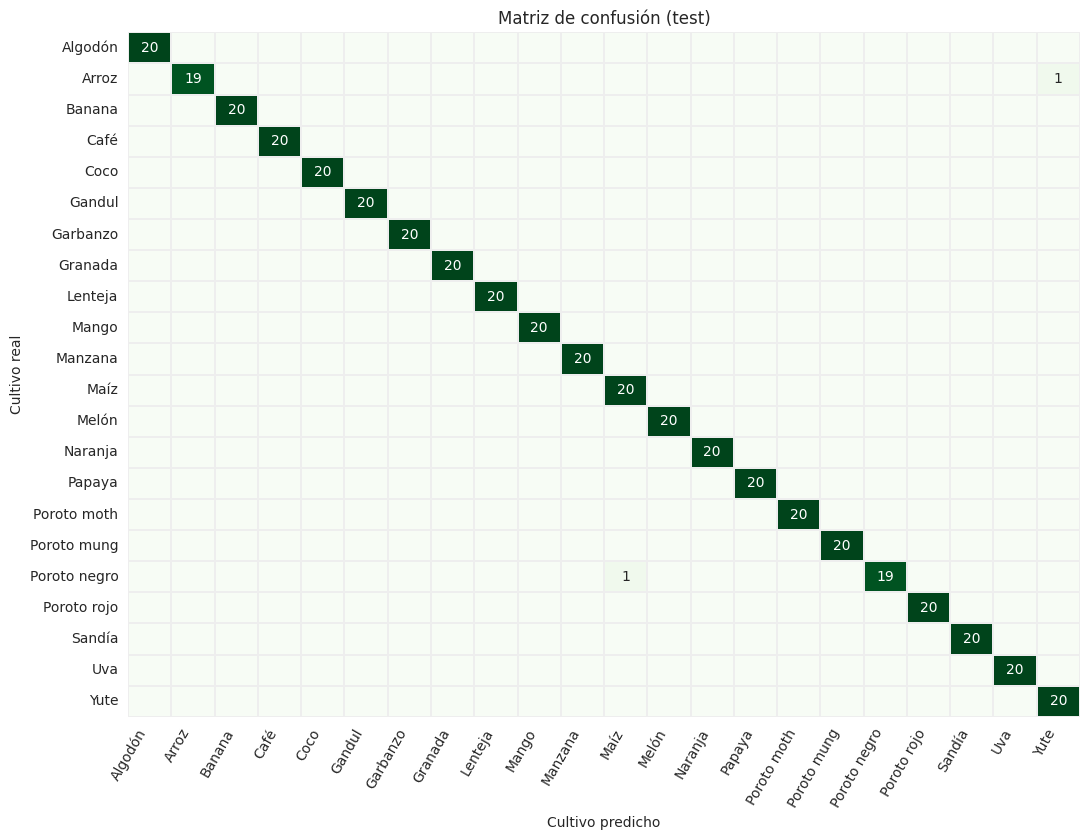

Parcelas mal clasificadas:


,real,predicho
178,Poroto negro,Maíz
378,Arroz,Yute


In [6]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
pred = rf.predict(X_te)
print(f"Accuracy en test : {accuracy_score(y_te, pred):.3f}")
print(f"F1 macro en test : {f1_score(y_te, pred, average='macro'):.3f}")
print(f"Errores          : {(pred != y_te).sum()} de {len(y_te)} parcelas")

clases = sorted(y_tr.unique()); cm = confusion_matrix(y_te, pred, labels=clases)
fig, ax = plt.subplots(figsize=(11, 8.5))
sns.heatmap(cm, annot=np.where(cm > 0, cm, ""), fmt="", cmap="Greens", cbar=False, xticklabels=clases,
            yticklabels=clases, linewidths=.3, linecolor="#eee", ax=ax)
ax.set_xlabel("Cultivo predicho"); ax.set_ylabel("Cultivo real"); ax.set_title("Matriz de confusión (test)")
plt.xticks(rotation=60, ha="right"); plt.tight_layout(); plt.show()

err = pd.DataFrame({"real": y_te.values, "predicho": pred}); err = err[err.real != err.predicho]
print("Parcelas mal clasificadas:"); display(err)

<div style="border-left:6px solid #3b6ea5;background:#eaf3fb;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🔎 Qué nos muestra</b><br>La <b>matriz de confusión</b> compara el cultivo real (filas) con el predicho (columnas): la diagonal son los aciertos. Casi todo está en la diagonal; hay <b>solo 2 errores en 440</b> parcelas: un <i>poroto negro</i> (<i>blackgram</i> en el original) predicho como maíz y un arroz predicho como yute. La confusión arroz ↔ yute tiene sentido: ambos piden clima cálido y húmedo.</div>

<div style="border-left:6px solid #b5651d;background:#fffaf2;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>⚠️ Ojo</b><br>Con 440 filas de test, 1 punto de accuracy equivale a unos 4 errores. Cualquier comparación entre modelos que difiera en 1 o 2 errores es <b>ruido</b>, no una diferencia real. En la versión completa, Naïve Bayes empata con este Random Forest.</div>

### 2.4 · ¿El modelo decide mirando una sola variable?

<div style="border-left:6px solid #2f6f4e;background:#f1f8f3;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🗣️ En criollo</b><br>Una duda importante: <b>¿el modelo se fija solo en una variable fuerte (por ejemplo la lluvia) e ignora todo lo demás?</b> Si fuera así, sería frágil y desperdiciaría información. Lo comprobamos de <b>tres formas independientes</b>; si todas coinciden, la conclusión es sólida.</div>

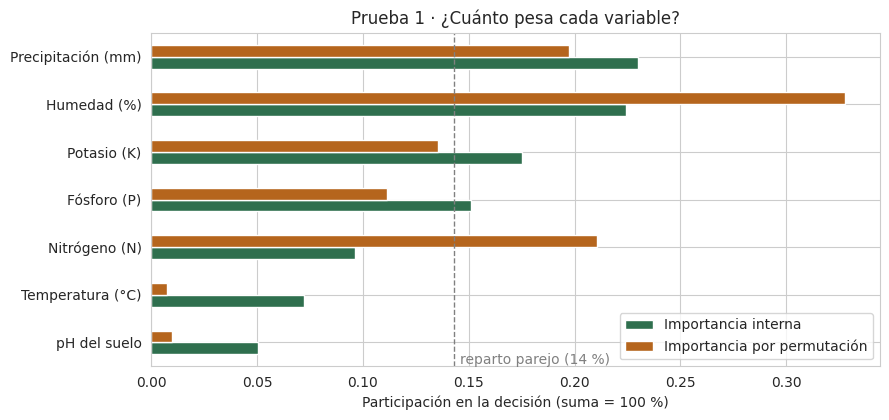

Más pesada: Precipitación (mm) (23.0%) | menos pesada: pH del suelo (5.1%)


In [7]:
from sklearn.inspection import permutation_importance

# Prueba 1: importancia interna (cuánto usó cada variable el bosque) y por permutación (cuánto empeora si la desordeno)
interna = pd.Series(rf.feature_importances_, index=VARS)
pi = permutation_importance(rf, X_te, y_te, n_repeats=15, random_state=SEED, n_jobs=-1)
perm = pd.Series(pi.importances_mean, index=VARS).clip(lower=0)
comp = pd.DataFrame({"Importancia interna": interna / interna.sum(), "Importancia por permutación": perm / perm.sum()}
                    ).sort_values("Importancia interna")
comp.plot.barh(figsize=(9, 4.3), color=["#2f6f4e", "#b5651d"])
plt.axvline(1/7, color="gray", ls="--", lw=1); plt.text(1/7 + .003, -.45, "reparto parejo (14 %)", color="gray")
plt.xlabel("Participación en la decisión (suma = 100 %)"); plt.title("Prueba 1 · ¿Cuánto pesa cada variable?")
plt.tight_layout(); plt.show()
print(f"Más pesada: {interna.idxmax()} ({interna.max()/interna.sum():.1%}) | menos pesada: {interna.idxmin()} ({interna.min()/interna.sum():.1%})")

Con las 7 variables: 0.994  |  azar: 0.045


,Sola,Sin ella (las otras 6),Caída al sacarla
Precipitación (mm),0.307,0.965,0.029
Humedad (%),0.316,0.981,0.013
Fósforo (P),0.219,0.989,0.005
Potasio (K),0.314,0.989,0.005
Nitrógeno (N),0.146,0.993,0.001
Temperatura (°C),0.174,0.993,0.001
pH del suelo,0.138,0.994,-0.001


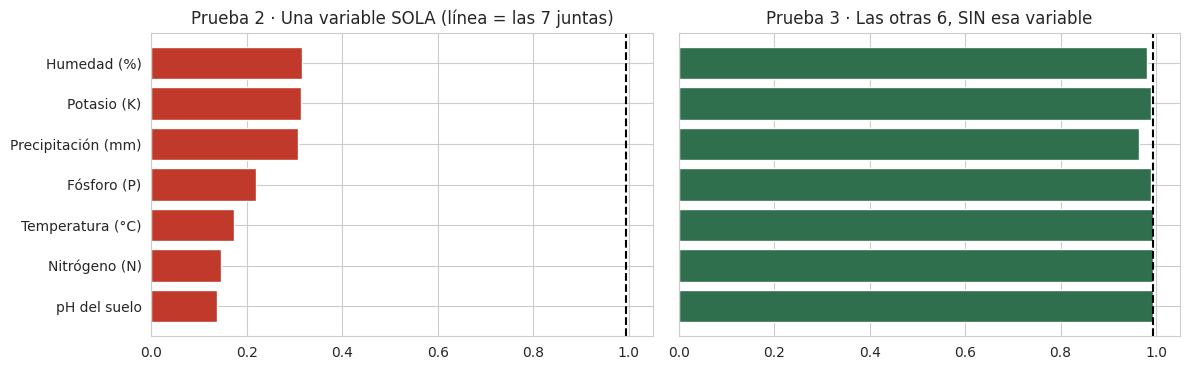

In [8]:
# Pruebas 2 y 3: cada variable SOLA  vs.  el modelo SIN esa variable
rf_rapido = RandomForestClassifier(n_estimators=150, random_state=SEED, n_jobs=-1)
nota = lambda cols: cross_validate(rf_rapido, X_tr[cols], y_tr, cv=cv, n_jobs=-1)["test_score"].mean()
todas = nota(VARS)
abl = pd.DataFrame({v: {"Sola": nota([v]), "Sin ella (las otras 6)": nota([c for c in VARS if c != v])} for v in VARS}).T
abl["Caída al sacarla"] = todas - abl["Sin ella (las otras 6)"]
print(f"Con las 7 variables: {todas:.3f}  |  azar: {1/22:.3f}")
display(abl.sort_values("Caída al sacarla", ascending=False))

orden = abl.sort_values("Sola").index
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
ax[0].barh(orden, abl.loc[orden, "Sola"], color="#c0392b"); ax[0].axvline(todas, color="k", ls="--"); ax[0].set_xlim(0, 1.05)
ax[0].set_title("Prueba 2 · Una variable SOLA (línea = las 7 juntas)")
ax[1].barh(orden, abl.loc[orden, "Sin ella (las otras 6)"], color="#2f6f4e"); ax[1].axvline(todas, color="k", ls="--"); ax[1].set_xlim(0, 1.05)
ax[1].set_title("Prueba 3 · Las otras 6, SIN esa variable")
plt.tight_layout(); plt.show()

<div style="border-left:6px solid #3b6ea5;background:#eaf3fb;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🔎 Qué nos muestra</b><br>
<ul>
<li><b>Ninguna variable alcanza sola:</b> la mejor llega a ~31 %, lejos del ~99 % del conjunto.</li>
<li><b>Sacar cualquiera casi no cambia nada:</b> la caída máxima es de apenas ~3 puntos (la lluvia). La información está <b>repartida y es redundante</b>.</li>
<li>La importancia interna muestra que la lluvia pesa ~23 % y el pH ~5 %: hay variables más importantes, pero <b>ninguna se lleva todo</b> (el reparto parejo sería 14 %).</li>
<li><b>Conclusión:</b> el conocimiento está en la <b>combinación</b> de variables. Es como un diagnóstico médico: la temperatura sola no diagnostica, pero junto con los demás síntomas sí.</li>
</ul></div>

### 2.5 · De la predicción a una recomendación útil: Top-3 con probabilidades

<div style="border-left:6px solid #2f6f4e;background:#f1f8f3;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🗣️ En criollo</b><br>Al productor no le sirve un solo nombre: le sirve <b>«te recomiendo A; B y C también son viables»</b>. El Random Forest da una probabilidad para cada cultivo, así que podemos ofrecer las 3 mejores opciones.</div>

In [9]:
proba = rf.predict_proba(X_te); top3 = rf.classes_[np.argsort(-proba, axis=1)[:, :3]]
print(f"El cultivo correcto es la 1.ª opción en el {np.mean(top3[:,0]==y_te.values):.1%} de los casos "
      f"y está entre las 3 primeras en el {np.mean([y_te.iloc[i] in top3[i] for i in range(len(y_te))]):.1%}")

def recomendar(parcela):
    p = pd.DataFrame([parcela])[VARS]
    return pd.Series(rf.predict_proba(p)[0], index=rf.classes_, name="Probabilidad").sort_values(ascending=False).head(3).to_frame()

parcela = dict(zip(VARS, [90, 42, 43, 21.0, 82.0, 6.5, 200.0]))
print("\nParcela de ejemplo:", parcela); recomendar(parcela)

El cultivo correcto es la 1.ª opción en el 99.5% de los casos y está entre las 3 primeras en el 100.0%

Parcela de ejemplo: {'Nitrógeno (N)': 90, 'Fósforo (P)': 42, 'Potasio (K)': 43, 'Temperatura (°C)': 21.0, 'Humedad (%)': 82.0, 'pH del suelo': 6.5, 'Precipitación (mm)': 200.0}


,Probabilidad
Arroz,0.880
Yute,0.120
Banana,0.000


<div style="border-left:6px solid #b5651d;background:#fffaf2;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>⚠️ Ojo</b><br>No ordenamos las alternativas por toneladas por hectárea: un cultivo que rinde más toneladas <b>no es necesariamente</b> el más conveniente (falta el <b>precio</b>) y algunos cultivos del dato oficial (como el yute) se informan en unidades que no son toneladas. La recomendación es una <b>ayuda para decidir</b>, no una orden.</div>

<div style="border-left:8px solid #2f6f4e;background:#f4f8f5;padding:16px 22px;margin:28px 0 12px 0;border-radius:0 8px 8px 0;"><div style="font-family:Georgia,serif;font-size:13px;letter-spacing:2px;color:#a04e14;font-weight:700;text-transform:uppercase;">Parte 3</div><div style="font-family:Georgia,serif;font-size:26px;font-weight:700;color:#143026;">Aprendizaje no supervisado: K-Means</div><div style="font-family:'Segoe UI',system-ui,sans-serif;font-size:16px;color:#3d4f47;margin-top:4px;">¿Qué grupos hay en los datos si no miramos el cultivo?</div></div>

<div style="border-left:6px solid #444;background:#f7f7f7;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🧩 Ficha del algoritmo</b><br><b>Cómo piensa:</b> elige <i>k</i> "centros" al azar, asigna cada parcela al centro más cercano, mueve cada centro al promedio de su grupo y repite hasta que nada cambia.
<br><b>Parámetro clave:</b> <code>k</code> (cuántos grupos): <b>hay que decidirlo nosotros</b>.
<br><b>Qué muestra:</b> si los datos tienen grupos naturales y qué los define.
<br><b>Requisito:</b> las variables deben estar en la <b>misma escala</b> (K-Means mide distancias; la lluvia, que va de 20 a 300, aplastaría al pH, que va de 3 a 9).</div>

<div style="border-left:6px solid #2f6f4e;background:#f1f8f3;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🗣️ En criollo</b><br>Es como entrar a un supermercado <b>sin carteles</b> y agrupar los productos por parecido. Si lo hacés bien, terminás reconstruyendo las secciones. Acá le damos las 2.200 parcelas <b>sin decirle qué cultivo es cada una</b>, y después comparamos con la verdad.</div>

### 3.1 · Preparación y una mirada en 2D con PCA

<div style="border-left:6px solid #2f6f4e;background:#f1f8f3;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🗣️ En criollo</b><br>No podemos dibujar 7 dimensiones. <b>PCA</b> las resume en 2, eligiendo el mejor "ángulo" para fotografiarlas. Lo usamos <b>solo para visualizar</b>, no para entrenar. (Como en la Etapa 1: con 7 variables casi no redundantes, comprimir no ayuda y se pierde interpretabilidad.)</div>

Con 2 componentes se conserva 46% de la información; con 5, 88%.


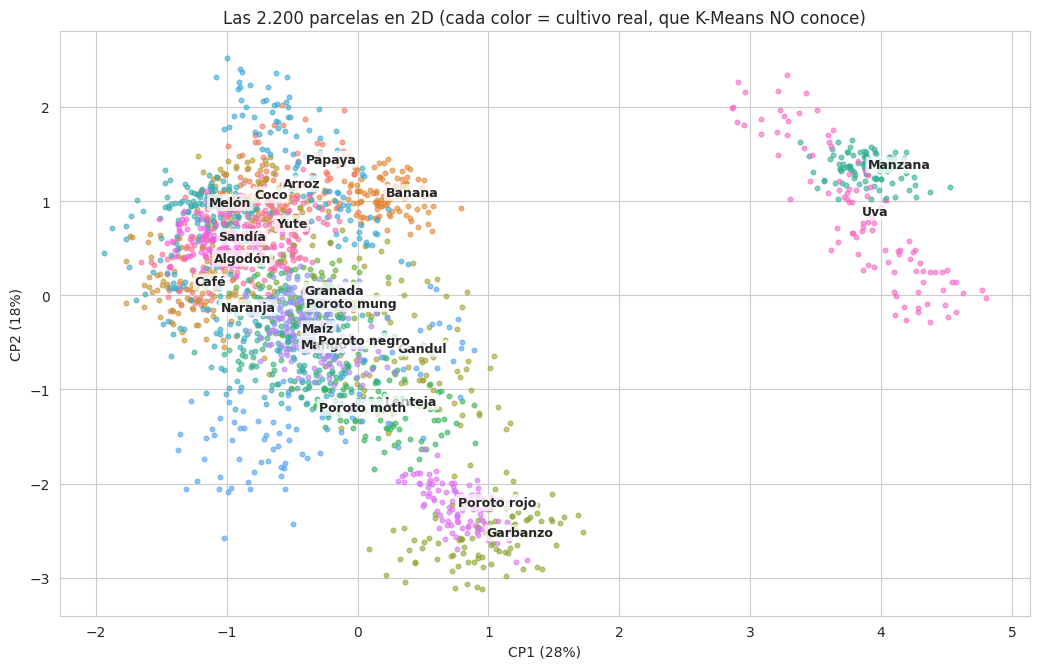

In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score, homogeneity_score, completeness_score

full = pd.concat([tr, te], ignore_index=True)            # las 2.200 parcelas; la etiqueta NO se usa para agrupar
Xs = StandardScaler().fit_transform(full[VARS]); y_real = full.Cultivo.values

pca = PCA().fit(Xs); ev = pca.explained_variance_ratio_
print(f"Con 2 componentes se conserva {ev[:2].sum():.0%} de la información; con 5, {ev[:5].sum():.0%}.")
Z = PCA(n_components=2).fit_transform(Xs)
paleta = sns.color_palette("husl", 22); orden = sorted(set(y_real))
fig, ax = plt.subplots(figsize=(10.5, 6.8))
for i, c in enumerate(orden):
    m = y_real == c; ax.scatter(Z[m, 0], Z[m, 1], s=11, color=paleta[i], alpha=.6)
    ax.text(Z[m, 0].mean(), Z[m, 1].mean(), c, fontsize=9, weight="bold", bbox=dict(boxstyle="round,pad=.15", fc="white", alpha=.75, lw=0))
ax.set_xlabel(f"CP1 ({ev[0]:.0%})"); ax.set_ylabel(f"CP2 ({ev[1]:.0%})")
ax.set_title("Las 2.200 parcelas en 2D (cada color = cultivo real, que K-Means NO conoce)"); plt.tight_layout(); plt.show()

<div style="border-left:6px solid #3b6ea5;background:#eaf3fb;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🔎 Qué nos muestra</b><br>Aun resumidas en 2 dimensiones, varios cultivos forman <b>islas bien definidas</b> y otros se solapan en el centro. Las otras 5 dimensiones ayudan a separarlos. Además, 2 componentes guardan solo ~46 % de la información: <b>la información está repartida</b>, igual que vimos en el supervisado.</div>

### 3.2 · ¿Cuántos grupos (k)? El codo y el silhouette

<div style="border-left:6px solid #2f6f4e;background:#f1f8f3;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🗣️ En criollo</b><br>K-Means no sabe cuántos grupos hay: se lo tenemos que decir. Dos pistas para elegir <i>k</i>: el <b>codo</b> (la inercia siempre baja al sumar grupos, pero hay un punto donde deja de bajar mucho) y el <b>silhouette</b> (qué tan bien separado está cada punto de los demás grupos, de −1 a 1).</div>

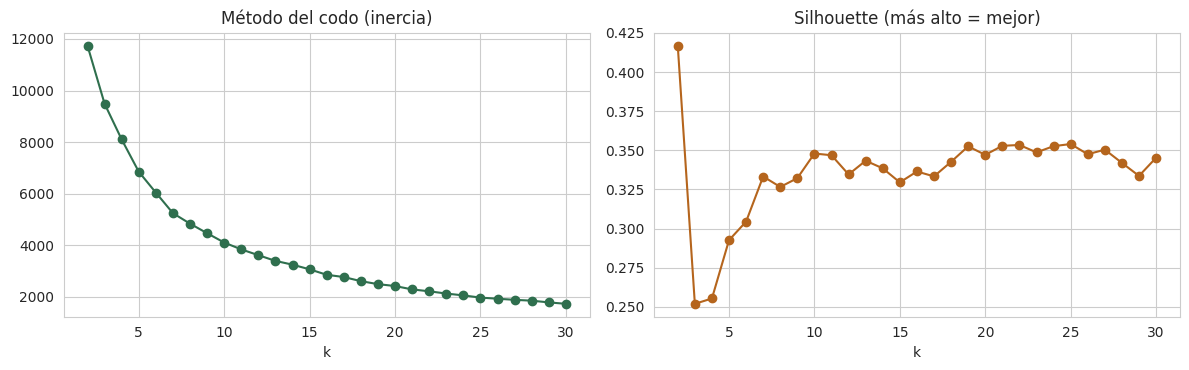

k con mejor silhouette: 2 (0.417)


In [11]:
ks = range(2, 31); inercia, silu = [], []
for k in ks:
    km = KMeans(k, n_init=10, random_state=SEED).fit(Xs); inercia.append(km.inertia_); silu.append(silhouette_score(Xs, km.labels_))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(ks, inercia, "o-", color="#2f6f4e"); ax[0].set_title("Método del codo (inercia)"); ax[0].set_xlabel("k")
ax[1].plot(ks, silu, "o-", color="#b5651d"); ax[1].set_title("Silhouette (más alto = mejor)"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.show()
print("k con mejor silhouette:", list(ks)[int(np.argmax(silu))], f"({max(silu):.3f})")

<div style="border-left:6px solid #3b6ea5;background:#eaf3fb;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🔎 Qué nos muestra</b><br>Las pistas <b>no dan un número claro</b>: no hay un codo nítido y el silhouette es máximo con <b>k = 2</b> (~0,42), o sea, dos "macro-grupos" que no reflejan los 22 cultivos. Esa falta de respuesta es información: la estructura es <b>jerárquica</b> (grupos dentro de grupos).
<br>Para evaluar con la realidad usamos <b>k = 22</b> sabiendo que hay 22 cultivos, <b>solo para comparar</b>.</div>

### 3.3 · K-Means con k = 22: ¿encontró los cultivos sin verlos?

Comparación con los cultivos reales:
  Índice de Rand ajustado (ARI)  : 0.676   (0 = azar, 1 = coinciden exacto)
  Homogeneidad  (¿cada grupo es de un solo cultivo?)  : 0.831
  Completitud   (¿cada cultivo cae en un solo grupo?) : 0.860


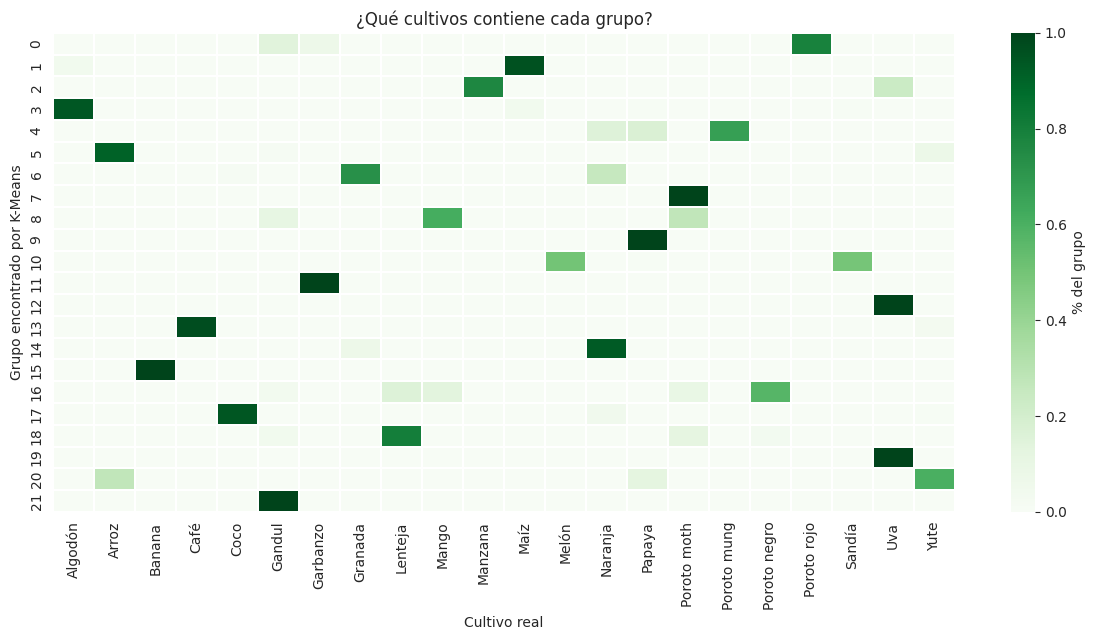

Pureza promedio: 85.0% | grupos 100 % puros: 7 de 22


In [12]:
km = KMeans(22, n_init=20, random_state=SEED).fit(Xs); etq = km.labels_
print("Comparación con los cultivos reales:")
print(f"  Índice de Rand ajustado (ARI)  : {adjusted_rand_score(y_real, etq):.3f}   (0 = azar, 1 = coinciden exacto)")
print(f"  Homogeneidad  (¿cada grupo es de un solo cultivo?)  : {homogeneity_score(y_real, etq):.3f}")
print(f"  Completitud   (¿cada cultivo cae en un solo grupo?) : {completeness_score(y_real, etq):.3f}")

ct = pd.crosstab(etq, y_real, normalize="index")
plt.figure(figsize=(12, 6.5)); sns.heatmap(ct, cmap="Greens", cbar_kws={"label": "% del grupo"}, linewidths=.2)
plt.xlabel("Cultivo real"); plt.ylabel("Grupo encontrado por K-Means"); plt.title("¿Qué cultivos contiene cada grupo?")
plt.tight_layout(); plt.show()
pureza = ct.max(axis=1); print(f"Pureza promedio: {pureza.mean():.1%} | grupos 100 % puros: {(pureza > .99).sum()} de 22")

<div style="border-left:6px solid #3b6ea5;background:#eaf3fb;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🔎 Qué nos muestra</b><br>
<ul>
<li>Sin ver ninguna etiqueta, K-Means <b>recupera buena parte de la estructura real</b>: ARI ≈ 0,68, pureza promedio ≈ 85 % y <b>7 de 22 grupos son 100 % de un solo cultivo</b> (una sola celda verde oscura en la fila).</li>
<li>No es perfecto: <i>melón y sandía</i> quedan en un mismo grupo, la <i>uva</i> se parte en dos y el <i>arroz</i> comparte grupo con yute y papaya. K-Means busca "bolas redondas" del mismo tamaño y los cultivos tienen formas y tamaños propios.</li>
<li>Diferencia con el supervisado: acá el algoritmo <b>descubre</b>; no <b>decide</b> con la precisión del Random Forest, que tuvo las respuestas a la vista.</li>
</ul></div>

#### ¿Qué significa cada grupo? (el "perfil" en unidades reales)

<div style="border-left:6px solid #2f6f4e;background:#f1f8f3;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🗣️ En criollo</b><br>Un grupo solo sirve si podemos <b>ponerle nombre</b>. Miramos el promedio de cada variable en cada grupo (en unidades reales, no escaladas) y qué cultivo domina.</div>

In [13]:
perfil = full[VARS].groupby(etq).mean()
perfil.insert(0, "Cultivo dominante", pd.Series(y_real).groupby(etq).agg(lambda s: s.value_counts().index[0]))
perfil.insert(1, "Pureza", pureza.values)
perfil.sort_values("Cultivo dominante").round(1)

,Cultivo dominante,Pureza,Nitrógeno (N),Fósforo (P),Potasio (K),Temperatura (°C),Humedad (%),pH del suelo,Precipitación (mm)
3,Algodón,0.900,116.800,46.400,20.100,24.100,79.600,6.900,80.800
5,Arroz,0.900,79.300,47.700,39.600,23.700,82.000,5.900,236.200
15,Banana,1.000,100.200,82.000,50.000,27.400,80.400,6.000,104.600
13,Café,1.000,101.000,29.200,30.200,25.500,59.200,6.800,158.300
17,Coco,0.900,22.100,17.400,29.700,27.600,94.600,6.000,173.300
21,Gandul,1.000,22.200,69.100,20.500,29.600,48.100,6.000,163.300
11,Garbanzo,1.000,41.000,67.900,79.800,18.900,17.000,7.500,79.800
6,Granada,0.700,18.200,17.700,32.300,22.500,90.700,6.500,108.900
18,Lenteja,0.800,19.600,65.900,19.500,23.600,63.100,6.700,49.800
8,Mango,0.600,19.600,36.600,26.000,30.500,50.600,5.200,84.100


<div style="border-left:6px solid #3b6ea5;background:#eaf3fb;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🔎 Qué nos muestra</b><br>Cada fila es un "tipo de ambiente": por ejemplo, los grupos dominados por <b>coco, arroz o papaya</b> tienen humedad y lluvia altas (coco: 95 % de humedad y 173 mm; arroz: 236 mm); los de <b>garbanzo y poroto rojo</b>, humedad muy baja (17 % y 24 %). Y la <b>uva</b> aparece en <b>dos grupos</b> que se distinguen sobre todo por la temperatura (~14 °C contra ~35 °C): el algoritmo descubrió que hay dos ambientes distintos donde la uva prospera. Es exactamente el tipo de lectura que haría un asesor técnico: <b>el algoritmo propone los grupos y el especialista les pone nombre</b>.</div>

### 3.4 · K-Means sobre el dato real: regiones agrícolas de India

<div style="border-left:6px solid #2f6f4e;background:#f1f8f3;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🗣️ En criollo</b><br>Ahora usamos el mismo algoritmo sobre el <b>dato oficial</b> (Dataset B). Para cada estado calculamos <b>qué porcentaje de su superficie sembrada</b> ocupa cada cultivo, y agrupamos los estados parecidos. Usamos <b>superficie</b> (no producción) a propósito: así las unidades inconsistentes del dato (el coco se cuenta en frutos) no distorsionan el resultado.</div>

In [14]:
d = pd.read_csv(RUTAS["limpio_B"], encoding="utf-8-sig")
d["Cultivo"] = d.Cultivo.replace(CULT_B); d["Estado"] = d.Estado.replace(ESTADO)
COLS_ID = ["Estado", "Distrito", "Anio", "Temporada", "Cultivo", "Area_ha", "Produccion_ton"]
n_dup = d.duplicated(COLS_ID).sum(); d = d.drop_duplicates(COLS_ID)       # arroz de Assam cargado dos veces (ver Taller 2b)
print(f"Se eliminaron {n_dup} filas duplicadas → {len(d):,} filas")

mezcla = d.groupby(["Estado", "Cultivo"]).Area_ha.sum().unstack(fill_value=0)
mezcla = mezcla.div(mezcla.sum(axis=1), axis=0)
M = mezcla[mezcla.mean().sort_values(ascending=False).head(15).index]      # los 15 cultivos más importantes

sil_e = {k: silhouette_score(M, KMeans(k, n_init=10, random_state=SEED).fit_predict(M)) for k in range(2, 9)}
display(pd.Series(sil_e, name="silhouette").to_frame().T)
K_E = max(sil_e, key=sil_e.get); km_e = KMeans(K_E, n_init=10, random_state=SEED).fit(M)
print("k elegido (mejor silhouette):", K_E)
for g in range(K_E):
    est = list(M.index[km_e.labels_ == g]); top = M[km_e.labels_ == g].mean().sort_values(ascending=False).head(3)
    print(f"\n🟢 Región {g+1} ({len(est)} estados): " + ", ".join(est))
    print("   Perfil:", ", ".join(f"{c} {v:.0%}" for c, v in top.items()))

Se eliminaron 0 filas duplicadas → 244,844 filas


,2,3,4,5,6,7,8
silhouette,0.382,0.387,0.431,0.371,0.400,0.390,0.354


k elegido (mejor silhouette): 4

🟢 Región 1 (8 estados): Bihar, Chandigarh, Haryana, Himachal Pradesh, Jammu y Cachemira, Punjab, Uttar Pradesh, Uttarakhand
   Perfil: Trigo 42%, Arroz 25%, Maíz 13%

🟢 Región 2 (14 estados): Arunachal Pradesh, Assam, Bengala Occidental, Chhattisgarh, Dadra y Nagar Haveli, Goa, Jharkhand, Manipur, Meghalaya, Mizoram, Nagaland, Odisha, Puducherry, Tripura
   Perfil: Arroz 69%, Maíz 5%, Castaña de cajú 2%

🟢 Región 3 (9 estados): Andhra Pradesh, Gujarat, Karnataka, Madhya Pradesh, Maharashtra, Rajasthan, Sikkim, Tamil Nadu, Telangana
   Perfil: Arroz 17%, Maíz 10%, Algodón 8%

🟢 Región 4 (2 estados): Islas Andamán y Nicobar, Kerala
   Perfil: Coco 53%, Arroz 19%, Castaña de cajú 3%


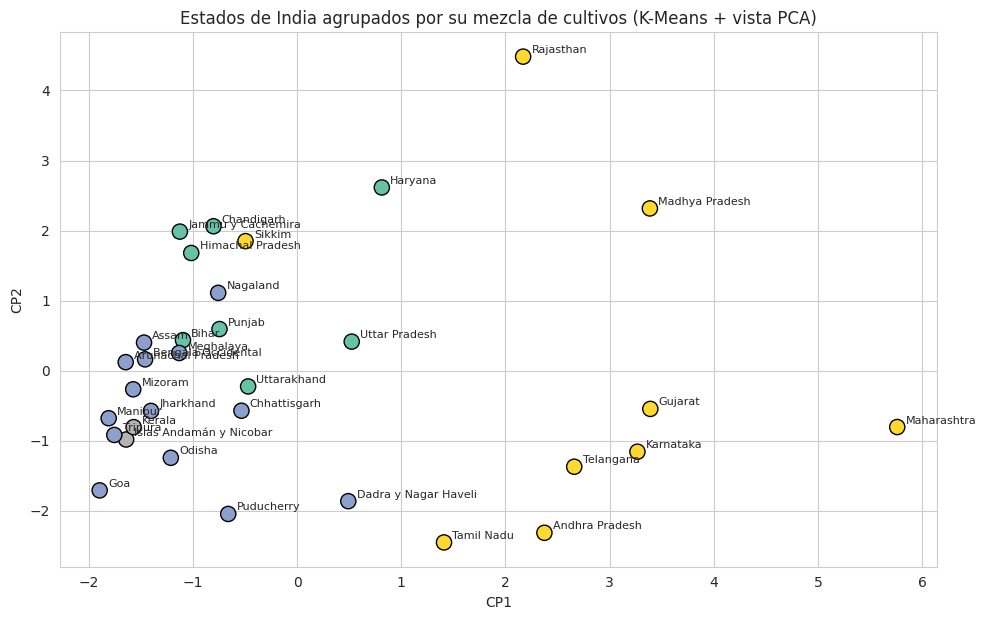

In [15]:
Z_e = PCA(n_components=2).fit_transform(StandardScaler().fit_transform(M))
fig, ax = plt.subplots(figsize=(10, 6.3))
ax.scatter(Z_e[:, 0], Z_e[:, 1], c=km_e.labels_, cmap="Set2", s=120, edgecolor="k")
for i, est in enumerate(M.index): ax.text(Z_e[i, 0] + .08, Z_e[i, 1] + .05, est, fontsize=8)
ax.set_title("Estados de India agrupados por su mezcla de cultivos (K-Means + vista PCA)"); ax.set_xlabel("CP1"); ax.set_ylabel("CP2")
plt.tight_layout(); plt.show()

<div style="border-left:6px solid #3b6ea5;background:#eaf3fb;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🔎 Qué nos muestra</b><br>Sin saber nada de geografía, K-Means reconstruye <b>4 regiones agrícolas reconocibles</b>: una <b>región arrocera</b> (arroz ≈ 69 %: este y noreste), la <b>franja triguera-arrocera del norte</b> (trigo ≈ 42 %), una zona <b>diversificada de secano</b> (algodón, maíz, arroz) y la <b>costa cocotera</b> (Kerala y Andamán, coco ≈ 53 %). Los estados de frontera conviene revisarlos con un experto: <b>Madhya Pradesh</b> (su perfil está justo en el límite entre la franja del trigo y la zona diversificada; al traducir los nombres cambió el orden de las columnas y pasó de una región a la otra) y <b>Sikkim</b> (muy pequeño). Es una lección: <b>los grupos de K-Means tienen bordes borrosos</b> y los estados del límite pueden cambiar de grupo con cambios mínimos en el cálculo.
<br><br><b>Y depende de datos limpios:</b> sin unificar <code>Paddy</code>/<code>Rice</code>, ni quitar las filas de totales, la mezcla de cada estado estaría distorsionada (ver Taller 2b).</div>

<div style="border-left:8px solid #2f6f4e;background:#f4f8f5;padding:16px 22px;margin:28px 0 12px 0;border-radius:0 8px 8px 0;"><div style="font-family:Georgia,serif;font-size:13px;letter-spacing:2px;color:#a04e14;font-weight:700;text-transform:uppercase;">Cierre</div><div style="font-family:Georgia,serif;font-size:26px;font-weight:700;color:#143026;">Conclusiones y limitaciones</div></div>

### ✅ Qué aprendimos
| | Random Forest (supervisado) | K-Means (no supervisado) |
|---|---|---|
| **Pregunta** | ¿Qué cultivo conviene? | ¿Qué grupos naturales hay? |
| **Resultado** | **99,5 %** de aciertos en test (2 errores en 440); el cultivo correcto está en el Top-3 el **100 %** de las veces | Sin ver etiquetas recupera los cultivos con ARI ≈ **0,68** y 4 regiones agrícolas de India |
| **Qué muestra** | Que el problema está bien estructurado y que **ninguna variable domina** | Que existen grupos reales, pero con forma jerárquica y solapes |
| **Rol de cada uno** | **Decide** con alta precisión | **Descubre** y propone; el experto interpreta |

**Se complementan:** el supervisado **responde** una pregunta que ya conocemos; el no supervisado **sugiere preguntas** que no teníamos.

### ⚠️ Limitaciones (decirlas antes de que pregunten)
- **El Dataset A es demasiado "perfecto"** (100 casos exactos por cultivo, muy separados): el ~99 % **no se trasladaría** tal cual al campo.
- **Los datos son de India**: no usarlos en otra región sin validación local.
- **No hay precios ni costos**: la recomendación es agronómica, no económica.
- **K-Means supone grupos redondos** y necesita que elijamos *k*. En la versión completa, la mezcla gaussiana lo mejora (ARI ≈ 0,94).

### 📎 Dónde está el resto
La versión completa (6 algoritmos supervisados, regresión de rendimiento, PCA, jerárquico y mezcla gaussiana) está en `Etapa2_Aprendizaje_Supervisado_y_No_Supervisado.ipynb`, y la limpieza de datos sucios en `Etapa2b_Taller_Limpieza_Datos_Sucios.ipynb`.